# Задание 1. Кластеризация исполнителей по жанрам

В этом задании необходимо кластеризовать исполнителей по жанрам на основе данных о прослушивании.


В файле music_listening.csv по строкам стоят пользователи, а по столбцам - исполнители.


Для каждой пары (пользователь,исполнитель) в таблице стоит число - доля (процент) прослушивания этого исполнителя выбранным пользователем.

### Импорт библиотек, загрузка данных

In [1]:
import pandas as pd

In [2]:
ratings = pd.read_csv('music_listening.csv', low_memory=False, thousands=',')

In [3]:
ratings.head()

,user,the beatles,radiohead,deathcab for cutie,coldplay,modest mouse,sufjan stevens,dylan. bob,red hot clili peppers,pink fluid,...,municipal waste,townes van zandt,curtis mayfield,jewel,lamb,michal w. smith,群星,agalloch,meshuggah,yellowcard
0,0,NaN,0.020417,NaN,NaN,NaN,NaN,NaN,0.030496,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,0.184962,0.024561,NaN,NaN,0.136341,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,NaN,NaN,0.028635,NaN,NaN,NaN,0.024559,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,0.043529,0.086281,0.034590,0.016712,0.015935,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Транспонируем матрицу ratings, чтобы по строкам стояли исполнители.

In [4]:
ratings = ratings.T
ratings.head()

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
user,0.000000,1.000000,2.000000,3.0,4.000000,5.000000,6.0,7.0,8.000000,9.000000,...,4990.000000,4991.0,4992.000000,4993.000000,4994.000000,4995.000000,4996.0,4997.000000,4998.0,4999.000000
the beatles,NaN,NaN,NaN,NaN,0.043529,NaN,NaN,NaN,0.093398,0.017621,...,NaN,NaN,0.121169,0.038168,0.007939,0.017884,NaN,0.076923,NaN,NaN
radiohead,0.020417,0.184962,NaN,NaN,0.086281,0.006322,NaN,NaN,NaN,0.019156,...,0.017735,NaN,NaN,NaN,0.011187,NaN,NaN,NaN,NaN,NaN
deathcab for cutie,NaN,0.024561,0.028635,NaN,0.034590,NaN,NaN,NaN,NaN,0.013349,...,0.121344,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.027893
coldplay,NaN,NaN,NaN,NaN,0.016712,NaN,NaN,NaN,NaN,NaN,...,0.217175,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Удалите строку под названием user.

In [5]:
ratings = ratings.drop('user')
ratings = ratings.astype(float)

Сколько строк осталось в матрице ratings?

In [6]:
print(ratings.shape[0])

1000


Заполните пропуски нулями.

In [7]:
ratings = ratings.fillna(0)

Нормализуйте данные при помощи normalize.

In [8]:
from sklearn.preprocessing import normalize

ratings_norm = normalize(ratings)

Примените KMeans с 5ю кластерами на преобразованной матрице (сделайте fit, а затем вычислите кластеры при помощи predict).

In [9]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(ratings_norm)
labels = kmeans.predict(ratings_norm)

Выведите на экран центры кластеров (центроиды)

In [10]:
centroids = kmeans.cluster_centers_
print(centroids)

[[ 1.74454937e-03  0.00000000e+00  1.26053127e-04 ...  0.00000000e+00
  -4.33680869e-19 -2.16840434e-19]
 [ 1.88589225e-03  1.06654937e-04  8.09463797e-04 ...  2.68938484e-03
  -6.50521303e-19  1.19757379e-03]
 [ 3.61253828e-04  1.46442378e-04  1.76373973e-03 ...  1.61495392e-04
   5.24534714e-03  4.35551103e-04]
 [-8.67361738e-19  1.66497739e-03  1.99868768e-03 ...  8.67029143e-03
  -6.50521303e-19 -6.50521303e-19]
 [ 2.09755947e-03  1.84497323e-03  1.64171427e-03 ...  3.70579584e-04
   1.54906547e-03  3.32336546e-03]]


Для каждого кластера найдем топ-10 исполнителей, наиболее близких к центроидам соотвествующего кластера.


Схожесть исполнителей будем считать по косинусной мере (spatial.distance.cosine).


Вычислите расстояние между "the beatles" и "coldplay". Ответ округлите до сотых.

In [11]:
from scipy import spatial

d = spatial.distance.cosine(ratings.loc['the beatles'], ratings.loc['coldplay'])
print(round(d, 2))

0.9


Ниже приведена функция, принимающая на вход:

- np.array points - все точки кластера
- pt - центроид кластера
- K = 10 - число

Функция возвращает K индексов объектов (строк в массиве points), ближайших к центроиду.

In [12]:
def pClosest(points, pt, K=10):
    ind = [i[0] for i in sorted(enumerate(points), key=lambda x: spatial.distance.cosine(x[1], pt))]
    return ind[:K]

Примените функцию pClosest (или придумайте свой подход) и выведите для каждого кластера названия топ-10 исполнителей, ближайших к центроиду.

In [13]:
import numpy as np

for i in range(5):
    mask = labels == i
    points = ratings_norm[mask]
    names = ratings.index[mask]
    top = pClosest(points, centroids[i], K=10)
    print(f'Кластер {i}:', list(names[top]))

Кластер 0: ['nas', 'jay-z', 'kanye west', 'lupe the gorilla', 'a tribe called quest', "the roots featuring d'angelo", 'little brother', "lil' wayne", 'gangstarr', 'the game']
Кластер 1: ['fall out boy', 'the all-americian rejects', 'paramore', 'kelly clarkson', 'john mayer', 'the fray', 'maroon5', 'dashboard confesssional', 'somethings corporate', 'coldplay']
Кластер 2: ['brand new', 'blink-182', 'alkaline trio', 'against me!', 'underoath', 'new found glory', 'descendents', 'thrice', 'less than jake', 'chiodos']
Кластер 3: ['the rolling stones', 'the beatles', 'dylan. bob', 'who', 'led zeppelin.', 'miles davis.', 'simon and garfunkel', 'young. neil', 'pink fluid', 'velvet underground']
Кластер 4: ['radiohead', 'the arcade fire', 'the shins', 'sufjan stevens', 'broken social scene', 'belle and sebastian', 'the pixies', 'animal collective', 'modest mouse', 'spoon']


Интерпретация. Посмотрите на списки исполнителей и опишите, что объединяет каждый кластер. Обычно кластеры соответствуют жанрам. Например, один кластер получается из рока и классики рока (The Beatles, Led Zeppelin), другой из инди и альтернативы (Coldplay, Radiohead), третий из хип-хопа или попа, четвёртый из электроники, а ещё один из метала. Кластеры отражают совместное прослушивание: исполнители попадают в один кластер, если их слушают одни и те же пользователи. Это совпадает с жанрами, но не обязано полностью им соответствовать. Ориентируйтесь на свои списки, а не на мои примеры.

# Задание 2. Сравнение алгоритмов кластеризации

Попробуйте разные методы для поиска кластеров. Не забудьте измерить время работы работы каждого метода.

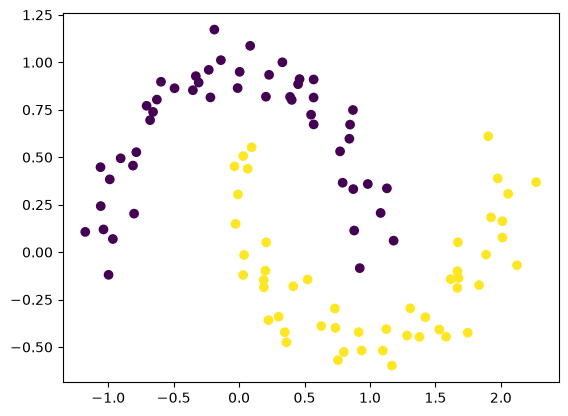

In [14]:
from matplotlib import pyplot as plt
from sklearn.datasets import make_moons
import time
from sklearn.metrics import adjusted_rand_score

data = make_moons(n_samples=100, noise=0.1, random_state=42)

X = data[0]
y = data[1]

plt.scatter(X[:,0], X[:,1], c=y)

def evaluate(model, X, y):
    start = time.perf_counter()
    pred = model.fit_predict(X)
    elapsed = time.perf_counter() - start
    return pred, adjusted_rand_score(y, pred), elapsed

### KMeans

Попробуйте найти кластеры при помощи KMeans

ARI=0.242, время=0.0026 с


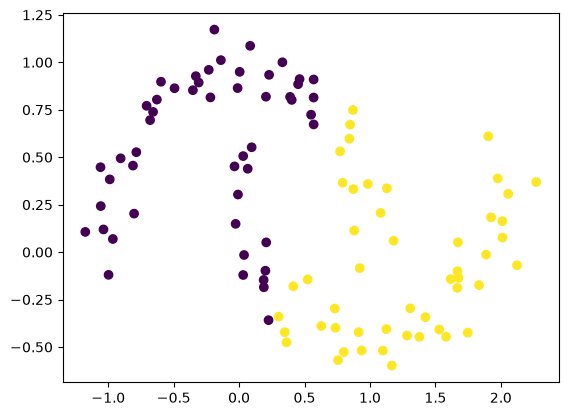

In [15]:
from sklearn.cluster import KMeans

pred, score, t = evaluate(KMeans(n_clusters=2, random_state=42), X, y)
print(f'ARI={score:.3f}, время={t:.4f} с')
plt.scatter(X[:, 0], X[:, 1], c=pred)
plt.show()

### DBSCAN

Подберите $\varepsilon$ и min_samples в DBSCAN, чтобы наилучшим образом найти кластеры.
Ищите гиперпараметры из диапазонов:
* eps in [0.05, 0.1, 0.2, 0.28, 0.3, 0.32]
* min_samples in [4, 5, 6, 7]

Лучшие параметры: eps=0.28, min_samples=4, ARI=1.000
ARI=1.000, время=0.0010 с


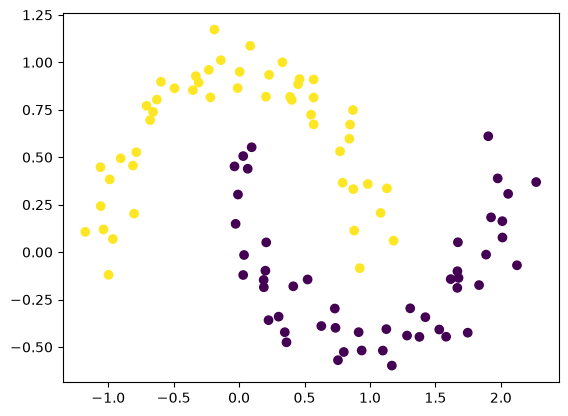

In [16]:
from sklearn.cluster import DBSCAN

best = (-1, None, None)
for eps in [0.05, 0.1, 0.2, 0.28, 0.3, 0.32]:
    for ms in [4, 5, 6, 7]:
        pred = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        score = adjusted_rand_score(y, pred)
        if score > best[0]:
            best = (score, eps, ms)
print(f'Лучшие параметры: eps={best[1]}, min_samples={best[2]}, ARI={best[0]:.3f}')

pred, score, t = evaluate(DBSCAN(eps=best[1], min_samples=best[2]), X, y)
print(f'ARI={score:.3f}, время={t:.4f} с')
plt.scatter(X[:, 0], X[:, 1], c=pred)
plt.show()

### Иерархическая кластеризация

Используйте иерархическую кластеризацию для поиска кластеров. Задайте в методе 2 кластера. Подберите гиперпараметр linkage из списка ['ward', 'complete', 'average', 'single'], дающий наилучший результат.

ward: ARI=0.223, время=0.0191 с
complete: ARI=0.404, время=0.0014 с
average: ARI=0.404, время=0.0006 с
single: ARI=1.000, время=0.0005 с
Лучший linkage: single


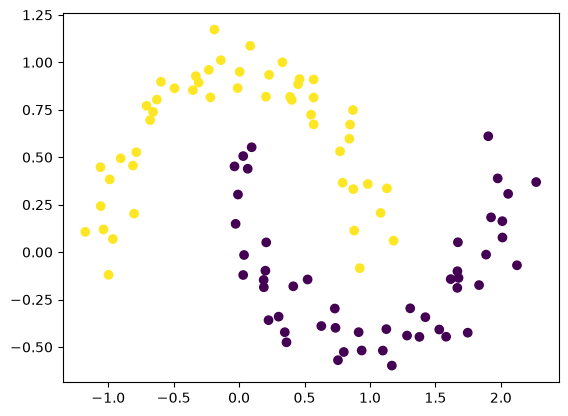

In [17]:
from sklearn.cluster import AgglomerativeClustering

res = {}
for link in ['ward', 'complete', 'average', 'single']:
    pred, score, t = evaluate(AgglomerativeClustering(n_clusters=2, linkage=link), X, y)
    res[link] = (score, t)
    print(f'{link}: ARI={score:.3f}, время={t:.4f} с')

best_link = max(res, key=lambda k: res[k][0])
print('Лучший linkage:', best_link)
pred = AgglomerativeClustering(n_clusters=2, linkage=best_link).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=pred)
plt.show()

### Спектральная кластеризация

Попробуйте найти кластеры при помощи спектральной кластеризации. Задайте 2 кластера, affinity='nearest_neighbors'. Подберите гиперпараметр n_neighbors из диапазона [1,2,...,19], чтобы добиться наилучшего результата.

Лучший n_neighbors=5, ARI=0.960, время=0.0097 с


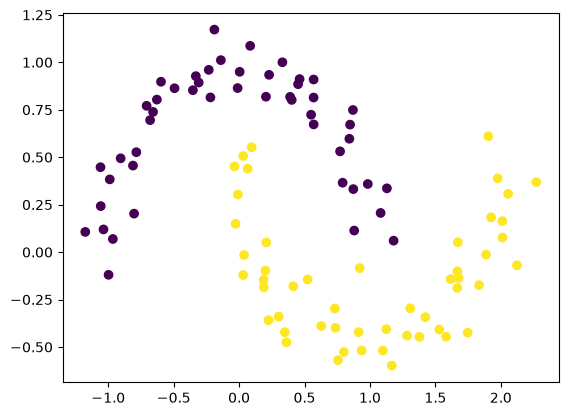

In [18]:
from sklearn.cluster import SpectralClustering
import warnings

res = {}

with warnings.catch_warnings():
    warnings.simplefilter('ignore', UserWarning)

    for k in range(1, 20):
        model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors',
                                   n_neighbors=k, random_state=42)
        pred, score, t = evaluate(model, X, y)
        res[k] = (score, t)

    best_k = max(res, key=lambda k: res[k][0])
    print(f'Лучший n_neighbors={best_k}, ARI={res[best_k][0]:.3f}, время={res[best_k][1]:.4f} с')

    pred = SpectralClustering(n_clusters=2, affinity='nearest_neighbors',
                              n_neighbors=best_k, random_state=42).fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=pred)
plt.show()

# Выводы

Сделайте выводы: какой метод сработал лучше других? какой метод сработал быстрее? есть ли метод, наилучший и по качеству, и по времени одновременно?

Качество. Лучше всех справились DBSCAN (eps=0.28, min_samples=4) и иерархическая кластеризация с linkage='single': у обоих ARI = 1.000, то есть кластеры найдены идеально. Спектральная кластеризация с n_neighbors=5 почти идеальна (ARI = 0.960). KMeans (0.242), ward (0.223), complete и average (по 0.404) справились плохо.


Почему так. «Луны» не выпуклые и вытянутые. KMeans и ward ищут компактные округлые кластеры, поэтому режут «луны» прямой линией. complete и average тоже ориентируются на компактность и расстояния между группами целиком. DBSCAN и single связывают точки по цепочке ближайших соседей и поэтому следуют форме «луны». Спектральная кластеризация строит граф ближайших соседей, который тоже учитывает форму, но для хорошего результата нужен достаточно большой n_neighbors, иначе граф распадается на несвязные части (отсюда предупреждения).


Время. Все методы отработали за доли секунды: single около 0.0005 с, DBSCAN около 0.0010 с, KMeans около 0.0026 с, спектральная около 0.0097 с, ward около 0.0191 с. Самыми медленными оказались ward и спектральная кластеризация. На 100 точках разница в доли миллисекунд сильно зависит от шума измерений, поэтому делать из неё строгие выводы нельзя.


Лучший метод по качеству и времени одновременно. Это DBSCAN и иерархическая кластеризация с single: у обоих идеальное качество при минимальном времени. DBSCAN удобнее тем, что не требует заранее задавать число кластеров. single на больших выборках может хуже масштабироваться (иерархические методы строят матрицу расстояний, то есть растут примерно квадратично по памяти и времени). Кроме того, у single есть склонность склеивать кластеры через шумовые точки-«мостики».